# Speech Technologies Project
## Late Fusion: XGBoost FER + SER Audio Models on RAVDESS

This notebook evaluates calibrated sum-fusion of SER audio encoders with an
XGBoost + Random Forest visual FER backbone trained on MediaPipe blendshape sequences.

### Research Questions
1. Under matched data splits and labels, how does frozen wav2vec 2.0 compare to LoRA-adapted wav2vec
2.0?
2. How does a specialized emotion foundation model (emotion2vec) compare to general wav2vec-based
pipelines?
3. Does calibrated late fusion with a visual XGBoostRF FER model improve unimodal performance?

### Methodological Principles
- **Label consistency:** `calm → neutral` across all experiments.
- **Data consistency:** actor-disjoint splits (16/4/4) shared by all SER and FER evaluations.
- **Fusion strategy:** calibrated temperature-scaled sum fusion only (no hybrid/shared-space).

### Experimental Plan
1. **Wav2Vec2 frozen linear probe** with layer-weighted pooling.
2. **Wav2Vec2 + LoRA probe** with weight-gating.
3. **emotion2vec forzen linear probe** with same linear probe as (1) but without the layer-weighted pooling.
4. **XGBoost + RF ensemble** on 369-dim blendshape statistics (velocity + inter-group ratios).
5. **Late fusion**: audio logits + XGBoost FER logits, temperature-calibrated and summed.

### Dataset
RAVDESS speech — 7-class label space (`calm` merged into `neutral`).

Whilst this notebook is guided and contains more visualisations (the confusion matrices), the full report with results dicussion is separate.

In [1]:
!pip install -q -U torchao peft
!pip install -q datasets transformers torchaudio soundfile
!pip install -q funasr
#might need to run this::
!pip install --upgrade git+https://github.com/huggingface/peft.git@main


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 37.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.6/43.6 kB 3.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 298.8/298.8 kB 9.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.7/89.7 kB 9.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 449.6/449.6 kB 24.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 926.2/926.2 kB 36.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 155.5/155.5 kB 18.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.0/6.0 MB 48.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.5/87.5 kB 10.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.5/99.5 kB 12.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.8/135.8 kB 17.0 MB/s eta 0:00:00


## Environment Setup and Imports



In [2]:

# ── 0. Environment Setup ─────────────────────────────────────
import sys
from datasets import config
sys.modules.pop('torchvision', None)
config.TORCHVISION_AVAILABLE = False


# ── 1. Imports (shared through Experiment 4) ─────────────────
import copy
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset, TensorDataset
from datasets import load_dataset
from transformers import Wav2Vec2Model, Wav2Vec2FeatureExtractor
from sklearn.metrics import classification_report, confusion_matrix
from tqdm.auto import tqdm
import torchaudio
import matplotlib.pyplot as plt
import seaborn as sns
from funasr import AutoModel
from torch.cuda.amp import autocast, GradScaler

# Set device

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

/usr/local/lib/python3.12/dist-packages/pydub/utils.py:300: SyntaxWarning: invalid escape sequence '\('
  m = re.match('([su]([0-9]{1,2})p?) \(([0-9]{1,2}) bit\)$', token)
/usr/local/lib/python3.12/dist-packages/pydub/utils.py:301: SyntaxWarning: invalid escape sequence '\('
  m2 = re.match('([su]([0-9]{1,2})p?)( \(default\))?$', token)
/usr/local/lib/python3.12/dist-packages/pydub/utils.py:310: SyntaxWarning: invalid escape sequence '\('
  elif re.match('(flt)p?( \(default\))?$', token):
/usr/local/lib/python3.12/dist-packages/pydub/utils.py:314: SyntaxWarning: invalid escape sequence '\('
  elif re.match('(dbl)p?( \(default\))?$', token):


## Global Configuration

All tunable constants are declared here so that any experiment parameter — model checkpoint, dataset identifier, audio sample rate, data paths — can be changed in one place without searching the notebook.

Key design choices:
- **`WAV2VEC2_MODEL_ID`** — `wav2vec2-base` (95 M parameters) is chosen over the large variant to keep fine-tuning tractable on a single GPU while still providing a strong pre-trained representation.
- **`EMOTION2VEC_MODEL_ID`** — the `emotion2vec_plus_base` checkpoint from ModelScope, selected over the standard base because its training corpus includes acted speech datasets similar to RAVDESS.
- **`TARGET_SR = 16 000 Hz`** — both Wav2Vec2 and emotion2vec were pre-trained at 16 kHz; resampling at load-time avoids any representation mismatch.
- **`MAX_SECONDS = 5.27 s`** — based on the max length ravdess file.


In [36]:
print(f"Using device: {DEVICE}")

# ── 2. Config ────────────────────────────────────────────────
WAV2VEC2_MODEL_ID = "facebook/wav2vec2-base"
EMOTION2VEC_MODEL_ID = "iic/emotion2vec_plus_base"
RAVDESS_DATASET_ID = "xbgoose/ravdess"
TARGET_SR    = 16_000
MAX_SECONDS  = 5.27
MAX_SAMPLES  = int(TARGET_SR * MAX_SECONDS)
SEED         = 42
BATCH_SIZE   = 8


# Path placeholders for notebook/runtime portability.
COLAB_DRIVE_MOUNT_POINT = "/content/drive"
BLENDSHAPE_DATA_PATH = "/content/drive/My Drive/ravdess-videos/blendshapes"
DATA_PATH = BLENDSHAPE_DATA_PATH


# Shared split and analysis config.
ACTOR_COUNTS = {"train": 16, "val": 4, "test": 4}
DIAGNOSTIC_PRINTS = 5

# emotion2vec output remapping config.
EMO2VEC_ID_TO_ENGLISH_LABEL = {
    0: "angry",
    1: "disgust",  # standardized from 'disgusted'
    2: "fearful",
    3: "happy",
    4: "neutral",
    5: "unk",      # standardized from 'other'
    6: "sad",
    7: "surprised",
    8: "unk",      # standardized from 'unknown'
}

# RAVDESS metadata mapping config.
INTENSITY_MAP = {1: "normal", 2: "strong"}
STATEMENT_MAP = {
    1: "Kids are talking by the door",
    2: "Dogs are sitting by the door",
}
REPETITION_MAP = {1: "1st repetition", 2: "2nd repetition"}
RAVDESS_EMOTION_ID_TO_NAME = {
    1: "neutral", 2: "calm", 3: "happy", 4: "sad",
    5: "angry", 6: "fearful", 7: "disgust", 8: "surprised",
}

# Label remap config for FER pretraining compatibility.
PRETRAIN_LABEL_REMAP = {"fear": "fearful"}

# FER preprocessing config.
FER_TARGET_FPS = 15
FER_TARGET_SECONDS = 5.0
FER_TARGET_FRAMES = int(FER_TARGET_FPS * FER_TARGET_SECONDS)  # 75


# Required columns from xbgoose/ravdess (validated after load).
RAVDESS_REQUIRED_COLUMNS = [
    "audio",
    "modality",
    "vocal_channel",
    "emotion",
    "emotional_intensity",
    "statement",
    "repetition",
    "actor",
    "gender",
]
# ── Checkpoint loading — set True to skip retraining on Colab restarts ────────
USE_CHECKPOINTS     = True
WAV2VEC2_PROBE_CKPT = "/content/drive/My Drive/speech project checkpoints/wav2vec2_linear_probe_weights.pt"
LORA_PROBE_CKPT     = "/content/drive/My Drive/speech project checkpoints/lora_wav2vec2_probe_weights.pt"
E2V_PROBE_CKPT =    "/content/drive/My Drive/speech project checkpoints/emotion2vec_base_lp_weights.pt"


Using device: cuda


In [4]:
from google.colab import drive

drive.mount(COLAB_DRIVE_MOUNT_POINT)

Mounted at /content/drive


In [20]:

def make_experiment_config(
    name,
    learning_rate,
    weight_decay,
    dropout,
    epochs=None,
    patience=None,
    use_class_weights=False,
):
    return {
        "name": name,
        "model": {
            "dropout": dropout,
        },
        "optimization": {
            "learning_rate": learning_rate,
            "weight_decay": weight_decay,
        },
        "training": {
            "epochs": epochs,
            "patience": patience,
        },
        "loss": {
            "type": "cross_entropy",
            "use_class_weights": use_class_weights,
            "class_weight_strategy": "inverse_frequency" if use_class_weights else None,
            "class_weights": None,
        },
        "eval_results": None,
        "other_details": "",
    }

experiment_1 = make_experiment_config(
    name="wav2vec frozen + linear probe",
    learning_rate=1e-3,
    weight_decay=1e-2,
    dropout=0.25,
    epochs=25,
    patience=5,
    use_class_weights=True,
)

experiment_2 = make_experiment_config(
    name="wav2vec LoRA",
    learning_rate=1e-3,
    weight_decay=1e-2,
    dropout=0.25,
    epochs=25,
    patience=5,
    use_class_weights=True,
)

experiment_3 = make_experiment_config(
    name="emotion2vec",
    learning_rate=1e-3,
    weight_decay=1e-4,
    dropout=0.20,
    epochs=50,
    patience=10,
    use_class_weights=True,
)




In [6]:
print("Loading dataset …")
raw = load_dataset(RAVDESS_DATASET_ID, split="train") #train is actually the entire dataset, no splits provided

missing_cols = [c for c in RAVDESS_REQUIRED_COLUMNS if c not in raw.column_names]
if missing_cols:
    raise ValueError(f"Missing expected RAVDESS columns: {missing_cols}")

all_emotions = sorted(list(set(raw["emotion"])))
# Merge 'calm' into 'neutral' at the source
EMOTION_MERGE_MAP = {"calm": "neutral"}
all_emotions = sorted(set(EMOTION_MERGE_MAP[e] if e in EMOTION_MERGE_MAP else e for e in all_emotions))
LABEL2ID = {e: i for i, e in enumerate(all_emotions)}
ID2LABEL = {i: e for e, i in LABEL2ID.items()}
NUM_CLASSES = len(LABEL2ID)

Loading dataset …


README.md:   0%|          | 0.00/669 [00:00<?, ?B/s]

data/train-00000-of-00002-94d632c9f1f51b(…): reconstructing file:   0%|          |  0.00B /  167MB            

data/train-00000-of-00002-94d632c9f1f51b(…): downloading bytes:           |  0.00B            

data/train-00001-of-00002-bcaf733d4b46d6(…): reconstructing file:   0%|          |  0.00B /  158MB            

data/train-00001-of-00002-bcaf733d4b46d6(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1440 [00:00<?, ? examples/s]

In [7]:
print(f"Num classes: {NUM_CLASSES} | Mapping: {LABEL2ID}")

# ── 4. Feature extractor & Preprocessing ─────────────────────
extractor = Wav2Vec2FeatureExtractor.from_pretrained(WAV2VEC2_MODEL_ID)

# Preprocess raw audio by resampling to 16kHz, padding/truncating to 5.27s.
# We keep both representations:
# - audio_16k: raw 16k waveform (for emotion2vec / other models)
# - input_values: wav2vec2-processed input values
def _standardize_waveform(arr: np.ndarray, eps: float = 1e-6) -> np.ndarray:
    arr = np.asarray(arr, dtype=np.float32)
    mean = float(arr.mean())
    std = float(arr.std())
    if std < eps:
        return np.zeros_like(arr, dtype=np.float32)
    return ((arr - mean) / std).astype(np.float32)

def preprocess(batch):
    audio_arrays = []
    for item in batch["audio"]:
        arr = np.array(item["array"], dtype=np.float32)
        sr  = item["sampling_rate"]
        if sr != TARGET_SR:
            arr = torchaudio.functional.resample(torch.from_numpy(arr), sr, TARGET_SR).numpy()
        if len(arr) > MAX_SAMPLES:
            arr = arr[:MAX_SAMPLES]
        else:
            arr = np.pad(arr, (0, MAX_SAMPLES - len(arr)))

        audio_arrays.append(arr)

    processed = extractor(audio_arrays, sampling_rate=TARGET_SR, return_tensors="np", padding=False)
    batch["audio_16k"] = audio_arrays
    batch["input_values"] = processed["input_values"]
    # Route through merge map
    batch["label"] = [LABEL2ID[EMOTION_MERGE_MAP.get(e, e)] for e in batch["emotion"]]
    return batch

Num classes: 7 | Mapping: {'angry': 0, 'disgust': 1, 'fearful': 2, 'happy': 3, 'neutral': 4, 'sad': 5, 'surprised': 6}


preprocessor_config.json:   0%|          | 0.00/159 [00:00<?, ?B/s]

In [8]:
print("Preprocessing audio …")
dataset = raw.map(preprocess, batched=True, batch_size=64, remove_columns=raw.column_names, desc="Feature Extraction")
dataset.set_format(type="torch", columns=["input_values", "label"], output_all_columns=True)

Preprocessing audio …


Feature Extraction:   0%|          | 0/1440 [00:00<?, ? examples/s]

## Data Split Protocol

We use **actor-disjoint** splits so that no speaker identity seen during training can appear in validation or test. It is necessary because the dataset contains 24 actors each contributing 60 utterances; a random split would leak speaker-specific vocal patterns and artificially inflate accuracy.

| Split | Actors | Samples |
|---|---|---|
| Train | 16 | 960 |
| Val | 4 | 240 |
| Test | 4 | 240 |

The 16 / 4 / 4 actor assignment is determined by a seeded shuffle (`SEED=42`) applied to the sorted actor list, ensuring exact reproducibility.

**Class label normalisation:** `calm` is merged into `neutral` across all experiments. emotion2vec does not expose a distinct `calm` output class, so keeping it separate for Wav2Vec2 but not for emotion2vec would define different classification tasks for each model, making direct comparison invalid.

## SpecAugment Optimisation on RAVDESS

*Spectral augmentation is applied to both wav2vec experiments.*

While the standard SpecAugment policy (Park et al., 2019) was designed for Automatic Speech Recognition (ASR), Speech Emotion Recognition (SER) requires specific adjustments to avoid destroying critical emotional prosody (pitch fluctuations and speech rate).

### 1. Validated Hyperparameter Policy

Based on recent SER literature, we apply the following constrained policy to preserve emotional context:

* **Frequency Mask Factor ($F$): 8–12 channels** (assuming a 128-bin Mel-spectrogram). This forces the network to learn robust acoustic textures without masking entire vowel or consonant harmonic ranges.
* **Time Mask Factor ($T$): 0–15 frames.** While ASR tolerates aggressive time masking, SER on RAVDESS requires $T \le 15$ to preserve temporal boundaries and rhythm—essential for distinguishing emotions like sadness (slow) from anger (fast) (Wang et al., 2020).
* **Time Warping ($W$): 0 (Disabled).** Studies confirm time warping provides negligible SER performance gains while introducing intense computational overhead.

### 2. Previous Research

* **Regularisation:** Masking directly on the spectrogram significantly aids in regularising deep convolutional networks (Baird et al., 2022).
* **Multi-Feature Fusion:** For optimal robustness on RAVDESS, spectrogram masking is deployed alongside waveform-level augmentations (e.g., random noise, pitch shifting) and frame-level feature integration (Mel-Spectrograms, MFCCs, Chroma vectors) (Chourasia et al., 2026; Madasu et al., 2025).

---

**References:**

1. Park, D. S., et al. (2019). *SpecAugment: A Simple Data Augmentation Method for Automatic Speech Recognition.*
2. Baird, L., et al. (2022). *A Comprehensive Evaluation of Canonical Deep Network Architectures and Data Augmentation Strategies for Speech Emotion Recognition.*
3. Chourasia, N., et al. (2026). *A 1D-CNN with advanced data augmentation for robust speech emotion recognition.*
4. Madasu, S., et al. (2025). *Speech Emotion Recognition on MELD and RAVDESS Datasets Using Multi-Feature Fusion and CNNs.*
5. Wang, H., et al. (2020). *Investigation of SpecAugment for Deep Acoustic and Speaker Embedding Learning.*

In [9]:
import numpy as np
from torch.utils.data import Subset, DataLoader

# Actor-aware split with explicit actor counts (16 train / 4 val / 4 test)

all_indices = np.arange(len(dataset))
all_actors = np.array(raw["actor"], dtype=int)
all_labels = np.array([LABEL2ID[EMOTION_MERGE_MAP.get(e, e)] for e in raw["emotion"]], dtype=int)

# Group sample indices by actor
actor_to_indices = {}
for idx, actor in enumerate(all_actors):
    actor_to_indices.setdefault(int(actor), []).append(idx)

actors = sorted(actor_to_indices.keys())
rng = np.random.default_rng(SEED)
rng.shuffle(actors)

# 2. Assign actors based on fixed counts
split_actor_lists = {
    "train": actors[:ACTOR_COUNTS["train"]],
    "val":   actors[ACTOR_COUNTS["train"] : ACTOR_COUNTS["train"] + ACTOR_COUNTS["val"]],
    "test":  actors[ACTOR_COUNTS["train"] + ACTOR_COUNTS["val"] :]
}

def indices_for_actors(actor_list):
    out = []
    for a in actor_list:
        out.extend(actor_to_indices[a])
    return sorted(out)

train_indices = indices_for_actors(split_actor_lists["train"])
val_indices   = indices_for_actors(split_actor_lists["val"])
test_indices  = indices_for_actors(split_actor_lists["test"])

# Build split datasets
train_ds = Subset(dataset, train_indices)
val_ds   = Subset(dataset, val_indices)
test_ds  = Subset(dataset, test_indices)

def collate_fn(batch):
    return {
        "input_values": torch.stack([b["input_values"] for b in batch]),
        "labels": torch.tensor([b["label"] for b in batch], dtype=torch.long),
    }

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn)
val_loader   = DataLoader(val_ds, batch_size=64, shuffle=False, collate_fn=collate_fn)
test_loader  = DataLoader(test_ds, batch_size=64, shuffle=False, collate_fn=collate_fn)

# Diagnostics
def _label_dist(indices):
    vals, cnt = np.unique(all_labels[indices], return_counts=True)
    return {ID2LABEL[int(v)]: int(c) for v, c in zip(vals, cnt)}

train_label_counts = np.bincount(all_labels[train_indices], minlength=NUM_CLASSES).astype(np.float32)
safe_label_counts = np.clip(train_label_counts, 1.0, None)
class_weights_np = (len(train_indices) / (NUM_CLASSES * safe_label_counts)).astype(np.float32)
class_weights = torch.tensor(class_weights_np, dtype=torch.float32, device=DEVICE)
experiment_1["loss"]["class_weights"] = {ID2LABEL[i]: float(class_weights_np[i]) for i in range(NUM_CLASSES)}

In [30]:
print("Actor counts per split:", {k: len(v) for k, v in split_actor_lists.items()})
print("Class dist (train): ", _label_dist(train_indices))
print("Sample counts:", {"train": len(train_indices), "val": len(val_indices), "test": len(test_indices)})
print("Class dist (val):", _label_dist(val_indices))
print("Class dist (test): ", _label_dist(test_indices))

Actor counts per split: {'train': 16, 'val': 4, 'test': 4}
Class dist (train):  {'angry': 128, 'disgust': 128, 'fearful': 128, 'happy': 128, 'neutral': 192, 'sad': 128, 'surprised': 128}
Sample counts: {'train': 960, 'val': 240, 'test': 240}
Class dist (val): {'angry': 32, 'disgust': 32, 'fearful': 32, 'happy': 32, 'neutral': 48, 'sad': 32, 'surprised': 32}
Class dist (test):  {'angry': 32, 'disgust': 32, 'fearful': 32, 'happy': 32, 'neutral': 48, 'sad': 32, 'surprised': 32}


# Experiment 1: Wav2Vec2 (Frozen) + Linear Probe

This baseline isolates how far a frozen SSL representation can go for SER when only a lightweight classifier and layer-weighted pooling are trained. The layer-weighted design tests whether emotion cues are distributed across intermediate transformer layers rather than concentrated only in the final block.

### Model Definition: Frozen Wav2Vec2 with Layer-Weighted Pooling and Linear Head

Backbone parameters are frozen. Trainable components are:
- a learnable weighting over transformer hidden layers
- a lightweight normalized linear classifier

This keeps the baseline efficient while preserving a strong representation from pretraining.

## Shared Training Infrastructure

The functions below are reused by every experiment to guarantee identical training conditions across models. Factoring them out eliminates copy-paste drift that could introduce subtle differences in early-stopping logic, metric tracking, or learning-rate scheduling.

`build_training_components` — constructs an **AdamW** optimiser and a **CosineAnnealingLR** scheduler from a validated experiment configuration dictionary. Using a config dict (rather than inline arguments) means every experiment's hyperparameters are declared once at the top of the notebook and referenced by name, which makes ablations easier to audit.

`train_model` — a generic epoch loop with:
- **AMP (Automatic Mixed Precision)** support via `torch.cuda.amp`, halving GPU memory footprint with negligible accuracy impact.
- **Early stopping** on validation loss to prevent overfitting on the small RAVDESS training split (960 utterances).
- **Best-checkpoint restoration** at the end of training so the returned model is always the one with lowest validation loss, not the final epoch.

`evaluate_test_set` — prints a per-class `sklearn` classification report and renders a labelled confusion matrix. Both are required by the evaluation protocol.

`predict_on_loader` — a batched inference helper that accumulates integer predictions across an entire DataLoader without materialising all logits in memory simultaneously.

In [13]:
#refactorchange
def build_training_components(model, experiment_config, class_weights=None):
    """Build optimizer/scheduler/criterion from a shared experiment config."""
    lr = experiment_config["optimization"]["learning_rate"]
    wd = experiment_config["optimization"]["weight_decay"]
    epochs = experiment_config["training"]["epochs"]
    patience = experiment_config["training"]["patience"]

    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=lr,
        weight_decay=wd,
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    criterion = nn.CrossEntropyLoss(
        weight=class_weights if experiment_config["loss"]["use_class_weights"] else None
    )
    return optimizer, scheduler, criterion, epochs, patience

def train_model(
    model,
    train_loader,
    val_loader,
    optimizer,
    scheduler,
    criterion,
    epochs,
    patience,
    device,
    model_name="Model",
    save_best=True,
    scheduler_step_per_batch=False,
    batch_to_xy_fn=None,
    use_amp = False
):
    """
    General high-level training loop with early stopping and learning rate scheduling.

    Args:
        model (torch.nn.Module): The model to train.
        train_loader (DataLoader): DataLoader for training data.
        val_loader (DataLoader): DataLoader for validation data.
        optimizer (torch.optim.Optimizer): Optimizer for model parameters.
        scheduler (torch.optim.lr_scheduler._LRScheduler): Learning rate scheduler.
        criterion (torch.nn.Module): Loss function.
        epochs (int): Total number of training epochs.
        patience (int): Number of epochs to wait for improvement before early stopping.
        device (torch.device): Device to run the training on (e.g., 'cuda', 'cpu').
        model_name (str): Name of the model for logging purposes.
        save_best (bool): Whether to save the best model state dictionary.
        scheduler_step_per_batch (bool): If True, step scheduler after each training batch.
        batch_to_xy_fn (callable): Optional function to map a batch to (x, y).
            If None, supports dict batches with keys input_values/labels and tuple/list batches (x, y).
        use_amp (bool): Whether to use Automatic Mixed Precision (AMP) for training.

    Returns:
        tuple: A tuple containing:
            - dict: Training history (train_loss, val_loss, lr).
            - dict or None: State dictionary of the best performing model on validation set, or None if save_best is False.
    """

    def _default_batch_to_xy(batch):
        if isinstance(batch, dict):
            return batch["input_values"], batch["labels"]
        if isinstance(batch, (tuple, list)) and len(batch) >= 2:
            return batch[0], batch[1]
        raise TypeError("Unsupported batch format. Provide batch_to_xy_fn for custom loaders.")

    if batch_to_xy_fn is None:
        batch_to_xy_fn = _default_batch_to_xy

    scaler = GradScaler() if use_amp else None

    def run_epoch(loader, current_model, is_train):
        current_model.train(is_train)
        total_loss, correct, total_n = 0.0, 0, 0
        desc = "Train" if is_train else "Val"
        pbar = tqdm(loader, desc=f"{model_name} Epoch [ {desc} ]", leave=False)
        for batch in pbar:
            x, y = batch_to_xy_fn(batch)
            x, y = x.to(device), y.to(device)

            optimizer.zero_grad()

            with torch.set_grad_enabled(is_train):
                if is_train and use_amp:
                    with autocast():
                        logits = current_model(x)
                        loss = criterion(logits, y)
                    scaler.scale(loss).backward()
                    scaler.step(optimizer)
                    scaler.update()
                else:
                    logits = current_model(x)
                    loss = criterion(logits, y)
                    if is_train:
                        loss.backward()
                        optimizer.step()

                if is_train and scheduler_step_per_batch and scheduler is not None:
                    scheduler.step()

            total_loss += loss.item() * y.size(0)
            correct += (logits.argmax(1) == y).sum().item()
            total_n += y.size(0)
            pbar.set_postfix({"acc": f"{correct/total_n:.2f}"})
        return total_loss / total_n, correct / total_n

    print(f"Starting {model_name} Training Loop …")
    best_val_loss = float('inf')
    best_model_state = None
    epochs_no_improve = 0
    history = {'train_loss': [], 'val_loss': [], 'lr': []}

    for epoch in range(1, epochs + 1):
        tr_loss, tr_acc = run_epoch(train_loader, model, is_train=True)
        vl_loss, vl_acc = run_epoch(val_loader, model, is_train=False)
        if (not scheduler_step_per_batch) and scheduler is not None:
            scheduler.step()
        current_lr = optimizer.param_groups[0]['lr']

        history['train_loss'].append(tr_loss)
        history['val_loss'].append(vl_loss)
        history['lr'].append(current_lr)

        print(f"Epoch {epoch:02d} | Train Loss: {tr_loss:.4f} Acc: {tr_acc:.3f} | Val Loss: {vl_loss:.4f} Acc: {vl_acc:.3f} | LR: {current_lr:.6f}")

        if vl_loss < best_val_loss:
            best_val_loss = vl_loss
            if save_best:
                best_model_state = copy.deepcopy(model.state_dict())
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"Early stopping triggered for {model_name}! Restoring best weights.")
                break

    if best_model_state is not None:
        model.load_state_dict(best_model_state)
        print(f"Training for {model_name} complete. Best Val Loss: {best_val_loss:.4f}")
    else:
        print(f"WARNING: No improvement was observed for {model_name} during training.")

    return history, best_model_state

#refactorchange
def evaluate_test_set(y_true, y_pred, id_to_label_map, model_name="Model"): # We will expand other metrics in the future
    """
    Evaluates model predictions on a test set, prints a classification report,
    and displays a confusion matrix.

    Args:
        y_true (list or np.ndarray): True labels of the test set.
        y_pred (list or np.ndarray): Predicted labels of the test set.
        id_to_label_map (dict): A dictionary mapping numerical IDs to class names.
        model_name (str): Name of the model for display in plots and reports.
    """
    print(f"\n--- {model_name} Test Set Evaluation ---")

    # Ensure inputs are numpy arrays
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    # Get active labels for the report and confusion matrix
    active_labels = sorted(list(np.unique(y_true)))
    target_names = [id_to_label_map[i] for i in active_labels]

    # Print Classification Report
    print(classification_report(y_true, y_pred, labels=active_labels, target_names=target_names, zero_division=0))

    # Generate Confusion Matrix
    cm = confusion_matrix(y_true, y_pred, labels=active_labels)

    # Plotting Confusion Matrix
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=target_names, yticklabels=target_names)
    plt.title(f'{model_name} - Confusion Matrix')
    plt.ylabel('Actual Label')
    plt.xlabel('Predicted Label')
    plt.show()

def predict_on_loader(model, loader, device, batch_to_xy_fn=None, desc="Testing"):
    """Run batched inference and return (labels, predictions)."""
    if batch_to_xy_fn is None:
        batch_to_xy_fn = lambda b: (b["input_values"], b["labels"])

    model.eval()
    preds, labels = [], []
    with torch.no_grad():
        for batch in tqdm(loader, desc=desc):
            x, y = batch_to_xy_fn(batch)
            x, y = x.to(device), y.to(device)
            preds.extend(model(x).argmax(1).cpu().tolist())
            labels.extend(y.cpu().tolist())
    return labels, preds

### 🔬 Experiment 1: Multi-Layer Feature Fusion (Wav2Vec 2.0 Probe)

**Motivation & Inspiration**
This architecture is directly inspired by the findings in *"Emotion Recognition from Speech Using Wav2vec 2.0 Embeddings"* (Pepino et al., 2021).

When extracting emotion from speech, the final hidden state of a pre-trained model doesn't always contain the whole picture. The authors demonstrated that earlier transformer layers often hold crucial acoustic features (like pitch and prosody) that get filtered out in later, more heavily contextualized layers.

To capture this, our model uses the pre-trained `wav2vec2-base` as a frozen feature extractor and pulls the outputs from **the local encoder and all 12 intermediate Transformer blocks**. These layers are then combined using a **trainable weighted average** initialized at 1.0, allowing the network to learn exactly which depths of the model are most useful for our specific emotion classes.

**Efficiency Adaptations**
To accommodate our project constraints, we adapted the authors' optimal "Dense" model into a highly parameter-efficient linear probe:
* **Temporal Feature Extraction:** Instead of using two sequential 128-neuron dense layers to process frame-level features, we streamlined it to a **single** 128-neuron linear layer (with ReLU and 0.2 Dropout) applied to the sequence *before* global mean pooling.
* **Normalization:** We utilize standard global/batch normalization over the inputs, bypassing the overhead of computing dynamic, speaker-dependent normalization statistics at runtime, as well as spectral augmentation.

---
**Reference:**
> Pepino, L., Riera, P., & Ferrer, L. (2021). Emotion Recognition from Speech Using Wav2vec 2.0 Embeddings. *arXiv preprint arXiv:2104.03502*. https://arxiv.org/abs/2104.03502

In [31]:
import torch
import torch.nn as nn
from transformers import Wav2Vec2Model, Wav2Vec2Config

class Wav2Vec2LinearProbe(nn.Module):
    def __init__(self, model_name: str, num_classes: int, dropout_prob: float = 0.2):
        super().__init__()

        # 1. Load config and explicitly inject SpecAugment settings into the backbone
        config = Wav2Vec2Config.from_pretrained(model_name)
        config.output_hidden_states = True # Ensure hidden states are outputted

        # SpecAugment equivalent settings for Wav2Vec2:
        config.mask_time_prob = 0.05      # Probability of masking a time step (Keep low for RAVDESS!)
        config.mask_time_length = 15      # Equivalent to max_time_mask = 15
        config.mask_feature_prob = 0.05   # Probability of masking a feature channel
        config.mask_feature_length = 12   # Equivalent to max_freq_mask = 12

        # 2. Load the pretrained Wav2Vec2 model with updated config
        self.backbone = Wav2Vec2Model.from_pretrained(model_name, config=config)

        # Freeze wav2vec2 backbone
        for p in self.backbone.parameters():
            p.requires_grad_(False)

        hidden_size = self.backbone.config.hidden_size

        # Total hidden states = num_hidden_layers + 1 (includes CNN feature extractor output)
        num_total_states = self.backbone.config.num_hidden_layers + 1

        # Create a learnable parameter initialized with ones to compute a weighted sum across all layers
        self.layer_weights = nn.Parameter(torch.ones(num_total_states))

        # Transform each weighted frame before pooling, matching the paper's lightweight head design
        self.frame_transformation = nn.Sequential(
            nn.Linear(hidden_size, 128),
            nn.ReLU(),
            nn.Dropout(dropout_prob),
        )
        # Final classifier after temporal pooling
        self.classifier = nn.Linear(128, num_classes)

    def forward(self, input_values: torch.Tensor) -> torch.Tensor:
        # Hugging Face natively applies SpecAugment to hidden states if self.training is True
        outputs = self.backbone(input_values)

        # Extract all layer representations and stack them (B, Num_Layers, Seq_Len, Hidden_Dim)
        hidden_states = torch.stack(outputs.hidden_states, dim=1)

        # Apply the softmax function to normalize layer weights into a probability distribution summing to one
        w = torch.softmax(self.layer_weights, dim=0)

        # Combine layers, then transform each time step before temporal pooling
        weighted_sum = (hidden_states * w[None, :, None, None]).sum(dim=1)
        frame_features = self.frame_transformation(weighted_sum)
        pooled = frame_features.mean(dim=1)

        return self.classifier(pooled)

# Instantiation mapping your original variables
wav2vec2_probe = Wav2Vec2LinearProbe(
    WAV2VEC2_MODEL_ID,
    NUM_CLASSES,
    dropout_prob=experiment_1["model"]["dropout"],
).to(DEVICE)

config.json:   0%|          | 0.00/1.84k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  380MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     |  | 
-----------------------------+------------+--+-
quantizer.codevectors        | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors: reconstructing file:   0%|          |  0.00B /  380MB            

model.safetensors: downloading bytes:           |  0.00B            

[Checkpoint] Loading Wav2Vec2 probe from /content/drive/My Drive/speech project checkpoints/wav2vec2_linear_probe_weights.pt ...
Checkpoint loaded — training skipped.


Testing LP:   0%|          | 0/4 [00:00<?, ?it/s]


--- Wav2Vec2 Linear Probe Test Set Evaluation ---
              precision    recall  f1-score   support

       angry       0.67      0.94      0.78        32
     disgust       0.84      0.66      0.74        32
     fearful       0.84      0.50      0.63        32
       happy       0.71      0.53      0.61        32
     neutral       0.73      0.98      0.84        48
         sad       0.47      0.53      0.50        32
   surprised       0.85      0.72      0.78        32

    accuracy                           0.71       240
   macro avg       0.73      0.69      0.70       240
weighted avg       0.73      0.71      0.71       240



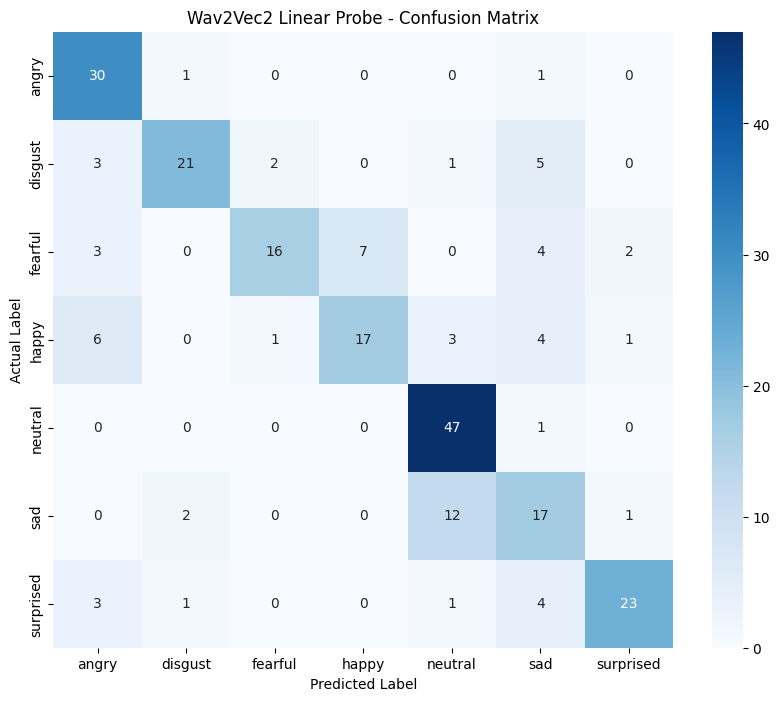

In [32]:
#refactorchange
# ── 7. Training or Checkpoint Load ───────────────────────────────────────────
if USE_CHECKPOINTS:
    print(f"[Checkpoint] Loading Wav2Vec2 probe from {WAV2VEC2_PROBE_CKPT} ...")
    wav2vec2_probe.load_state_dict(torch.load(WAV2VEC2_PROBE_CKPT, map_location=DEVICE))
    wav2vec2_probe.eval()
    print("Checkpoint loaded — training skipped.")
else:
    optimizer, scheduler, criterion, EPOCHS, PATIENCE = build_training_components(
        model=wav2vec2_probe,
        experiment_config=experiment_1,
        class_weights=class_weights,
    )
    history, best_model_state = train_model(
        model=wav2vec2_probe,
        train_loader=train_loader,
        val_loader=val_loader,
        optimizer=optimizer,
        scheduler=scheduler,
        criterion=criterion,
        epochs=EPOCHS,
        patience=PATIENCE,
        device=DEVICE,
        model_name="Wav2Vec2 Linear Probe",
        use_amp=True,
    )

#refactorchange
# ── 8. Evaluation ─────────────────────────────────────────────────────────────
all_labels, all_preds = predict_on_loader(
    model=wav2vec2_probe,
    loader=test_loader,
    device=DEVICE,
    desc="Testing LP",
)

evaluate_test_set(all_labels, all_preds, ID2LABEL, model_name="Wav2Vec2 Linear Probe")

# Experiment 2: Wav2Vec2 + LoRA Probe

Full fine-tuning can overfit on relatively small SER datasets. LoRA provides a parameter-efficient alternative that adapts attention projections while retaining most pretrained structure.

We replace the papers 2-layer downstream classifier with a lightweight single-stage head (LayerNorm plus a single linear output layer) to isolate the impact of PEFT modules.

### 🔬 Experiment 2: Parameter-Efficient Fine-Tuning (LoRA + WS + WG)

**Motivation & Inspiration**
Building on our baseline, this experiment integrates the Parameter-Efficient Fine-Tuning (PEFT) strategy proposed in *"Parameter Efficient Finetuning for Speech Emotion Recognition and Domain Adaptation"* (Lashkarashvili et al., 2024). The authors demonstrated that combining specific PEFT modules can surpass full model fine-tuning while updating only a fraction of the parameters.

**Architectural Design & Ablation Strategy**
To strictly isolate the impact of the upstream PEFT interventions, we intentionally deviate from the paper's 2-layer downstream classifier and retain the exact **single-layer linear probe** used in Experiment 1.

Our active interventions are:
1. **LoRA (Low-Rank Adaptation):** Applied to the `q_proj` and `v_proj` attention matrices with a heavily restricted rank ($r=4$) to prevent overfitting while allowing the backbone to learn temporal emotional dynamics.
2. **WG (Weight-Gating):** A learnable gating vector applied via sigmoid activation to the hidden states, allowing the network to mask out irrelevant acoustic features and amplify emotion-specific ones.
3. **WS (Weighted Sum):** A trainable softmax-normalized summation of all transformer layers to capture features across all depths of the network.

we apply the same regularisation and augmentation techniques as the first experiment.

---
**Reference:**
> Lashkarashvili, N., Wu, W., Sun, G., & Woodland, P. C. (2024). Parameter Efficient Finetuning for Speech Emotion Recognition and Domain Adaptation. *arXiv preprint arXiv:2402.11747*. https://arxiv.org/abs/2402.11747

### LoRA Architecture and PEFT Justification

See the Research Notes cell below for a detailed discussion of SpecAugment hyperparameter choices. The LoRA configuration (`r=4`, `lora_alpha=4`) is intentionally conservative:

- **Rank $r=4$** gives the adapter only 4 independent directions to update per weight matrix, drastically limiting overfitting capacity on 960 training utterances.
- **`lora_alpha=4`** keeps the effective learning-rate multiplier at 1.0 (`lora_alpha / r = 1`), meaning LoRA does not amplify the adapter gradients.
- LoRA is applied only to `q_proj` and `v_proj` in each attention layer, leaving the value and feed-forward weights frozen, because query–key interactions are most critical for temporal alignment while feed-forward weights encode factual knowledge less relevant to prosody.

In [50]:
import torch
import torch.nn as nn
from transformers import Wav2Vec2Model, Wav2Vec2Config
from peft import LoraConfig, get_peft_model

class Wav2Vec2LoRAProbe(nn.Module):
    def __init__(self, model_name: str, num_classes: int):
        super().__init__()

        # 1. Load config and explicitly inject SpecAugment settings into the backbone
        # This replaces the custom SpecAugment class safely
        config = Wav2Vec2Config.from_pretrained(model_name)
        config.output_hidden_states = True # Ensure hidden states are outputted

        # SpecAugment equivalent settings for Wav2Vec2:
        config.mask_time_prob = 0.05      # Probability of masking a time step (Keep low for RAVDESS!)
        config.mask_time_length = 15      # Equivalent to max_time_mask = 15
        config.mask_feature_prob = 0.05   # Probability of masking a feature channel
        config.mask_feature_length = 12   # Equivalent to max_freq_mask = 12

        # 2. Load base model with updated config
        base_model = Wav2Vec2Model.from_pretrained(model_name, config=config)

        peft_config = LoraConfig(
            r=4,                           # Choke capacity to kill actor memory
            lora_alpha=4,                  # Multiplier at 1.0 (no amplification)
            target_modules=["q_proj", "v_proj"],
            lora_dropout=0.25,
            bias="none",
            task_type="FEATURE_EXTRACTION"
        )

        # 3. Wrap with PEFT
        self.backbone = get_peft_model(base_model, peft_config)
        hidden_size = self.backbone.config.hidden_size

        # Total hidden states = num_hidden_layers + 1 (includes CNN feature extractor output)
        num_total_states = self.backbone.config.num_hidden_layers + 1

        # WG adaptor (feature-dimension gate) + WS adaptor (layer-weighted sum)
        self.layer_weights = nn.Parameter(torch.ones(num_total_states))
        self.weight_gate = nn.Parameter(torch.ones(hidden_size))

        self.classifier = nn.Sequential(
            nn.LayerNorm(hidden_size),
            nn.Linear(hidden_size, num_classes)
        )

    def forward(self, input_values: torch.Tensor) -> torch.Tensor:
        # Pass directly into the backbone.
        # Hugging Face natively applies SpecAugment to hidden states if self.training is True.
        outputs = self.backbone(input_values=input_values)

        # outputs.hidden_states is a tuple of length (num_layers + 1)
        hidden_states = torch.stack(outputs.hidden_states, dim=1) # (B, Num_Layers, Seq_Len, Hidden_Dim)

        # Apply the feature-dimension gate
        gated_hidden_states = torch.sigmoid(self.weight_gate) * hidden_states

        # Softmax normalize over all layers
        w = torch.softmax(self.layer_weights, dim=0)

        # Weighted sum across layers, then mean-pool across sequence length (time)
        pooled = (gated_hidden_states * w[None, :, None, None]).sum(dim=1).mean(dim=1)

        return self.classifier(pooled)

### Training the LoRA-Enhanced Probe

We train LoRA with the same AdamW + CosineAnnealingLR + early-stopping setup as Experiment 1.

In [51]:
#refactorchange
#w2vlpchange
# Upgrade torchao and peft to resolve version incompatibility

# Initialize the LoRA model
lora_model = Wav2Vec2LoRAProbe(WAV2VEC2_MODEL_ID, NUM_CLASSES).to(DEVICE)
trainable_lora = sum(p.numel() for p in lora_model.parameters() if p.requires_grad)

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     |  | 
-----------------------------+------------+--+-
quantizer.codevectors        | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
[transformers] Wav2Vec2Model does not expose input embeddings. Gradients cannot flow back to the token embeddings when using adapters or gradient checkpointing. Override `get_input_embeddings` to fully support those features, or set `_input_embed_layer` to the attribute name that holds the embeddings.


In [52]:
print(f"Trainable params (LoRA): {trainable_lora:,}")

# ── Training or Checkpoint Load ───────────────────────────────────────────────
if USE_CHECKPOINTS:
    print(f"[Checkpoint] Loading LoRA probe from {LORA_PROBE_CKPT} ...")
    lora_model.load_state_dict(torch.load(LORA_PROBE_CKPT, map_location=DEVICE))
    lora_model.eval()
    print("Checkpoint loaded — training skipped.")
else:
    optimizer_lora, scheduler_lora, criterion_lora, EPOCHS_LORA, PATIENCE_LORA = build_training_components(
        model=lora_model,
        experiment_config=experiment_2,
        class_weights=class_weights,
    )
    history_lora, best_lora_state = train_model(
        model=lora_model,
        train_loader=train_loader,
        val_loader=val_loader,
        optimizer=optimizer_lora,
        scheduler=scheduler_lora,
        criterion=criterion_lora,
        epochs=EPOCHS_LORA,
        patience=PATIENCE_LORA,
        device=DEVICE,
        model_name="Wav2Vec2 LoRA Probe",
        use_amp=True,
    )

#refactorchange
#w2vlpchange

Trainable params (LoRA): 155,156
[Checkpoint] Loading LoRA probe from /content/drive/My Drive/speech project checkpoints/lora_wav2vec2_probe_weights.pt ...
Checkpoint loaded — training skipped.


In [53]:
print("\nEvaluating LoRA Model on Test Set …")
lora_labels, lora_preds = predict_on_loader(
    model=lora_model,
    loader=test_loader,
    device=DEVICE,
    desc="Testing LoRA",
)


Evaluating LoRA Model on Test Set …


Testing LoRA:   0%|          | 0/4 [00:00<?, ?it/s]


--- Wav2Vec2 LoRA Probe Test Set Evaluation ---
              precision    recall  f1-score   support

       angry       0.65      1.00      0.79        32
     disgust       0.73      0.50      0.59        32
     fearful       0.81      0.81      0.81        32
       happy       1.00      0.38      0.55        32
     neutral       0.74      0.96      0.84        48
         sad       0.47      0.50      0.48        32
   surprised       0.90      0.81      0.85        32

    accuracy                           0.72       240
   macro avg       0.76      0.71      0.70       240
weighted avg       0.76      0.72      0.71       240



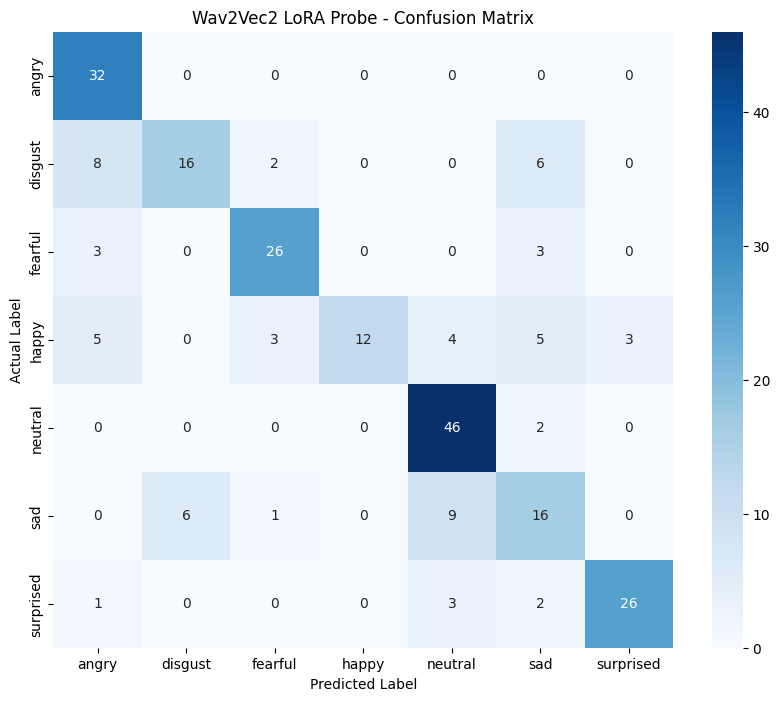

In [ ]:
evaluate_test_set(lora_labels, lora_preds, ID2LABEL, model_name="Wav2Vec2 LoRA Probe")

# --- Step 1: Permanently Freeze lora_model for Fusion ---
# This explicit freeze is critical: it prevents the LoRA adapters from receiving
# gradient updates during the Hybrid-Fusion training phase, ensuring they act
# strictly as a fixed feature extractor even in contexts outside of torch.no_grad().

lora_model.eval()
for p in lora_model.parameters():
    p.requires_grad_(False)

trainable_after = sum(p.numel() for p in lora_model.parameters() if p.requires_grad)

## Experiment 3: emotion2vec Linear Probe Evaluation

This experiment evaluates the **foundational representation quality** of the `emotion2vec` backbone using a linear probing methodology. The upstream model parameters are strictly frozen, and a lightweight downstream classification head is trained directly on the RAVDESS dataset.

To ensure a rigorously controlled comparison against the *wav2vec* baseline, the custom classifier is architecturally identical (a two-layer linear network with 128 hidden units and a dropout layer). By passing both models through the exact same bottleneck, this isolates the upstream embeddings as the sole variable.

This experiment answers Research Question 1 directly: *how do the frozen representations of a dedicated SER foundation model compare to a general-purpose speech model on RAVDESS?*

In [ ]:
print("Extracting raw audio using test_indices for fair comparison...")
audio_list_emo2vec = []
true_labels_emo2vec = []

# Select the exact same raw samples used in the test split
test_raw_dataset = raw.select(test_indices)

for i, item in enumerate(tqdm(test_raw_dataset, desc="Processing raw test audio")):
    # 1. Get the raw un-normalized waveform
    arr = np.array(item["audio"]["array"], dtype=np.float32)
    sr = item["audio"]["sampling_rate"]

    # 2. emotion2vec strictly requires 16kHz audio
    if sr != TARGET_SR:
        arr = torchaudio.functional.resample(torch.from_numpy(arr), sr, TARGET_SR).numpy()

    audio_list_emo2vec.append(arr.flatten())

    # 3. Pull the ground truth label string directly using your ID2LABEL mapping
    # to guarantee it matches your Wav2Vec2 linear probe's evaluation alignment
    label_id = test_ds[i]["label"].item()
    label_str = ID2LABEL[label_id]
    true_labels_emo2vec.append(label_str)

Extracting raw audio using test_indices for fair comparison...


Processing raw test audio:   0%|          | 0/240 [00:00<?, ?it/s]

Rather than the emtion2vec+ base which is finetuned for classification using teacher-student distillation, with a teacher that has seen ravdess, we see what emotion2vec performs like with our own light weight classifier head trained on ravdess.

funasr version: 1.3.14.


2026-07-16 19:49:25,024 | INFO    | modelscope_hub.download | Downloading 9 files from iic/emotion2vec_base@master


Downloading:   0%|          | 0/9 [00:00<?, ?file/s]

[Checkpoint] Loading emotion2vec probe from /content/drive/My Drive/speech project checkpoints/emotion2vec_base_lp_weights.pt ...
Checkpoint loaded — training skipped.


Testing emo2vec LP:   0%|          | 0/4 [00:00<?, ?it/s]


--- emotion2vec Base LP Test Set Evaluation ---
              precision    recall  f1-score   support

       angry       0.62      0.72      0.67        32
     disgust       0.66      0.66      0.66        32
     fearful       0.80      0.75      0.77        32
       happy       0.56      0.44      0.49        32
     neutral       0.72      0.92      0.81        48
         sad       0.43      0.38      0.40        32
   surprised       0.96      0.81      0.88        32

    accuracy                           0.68       240
   macro avg       0.68      0.67      0.67       240
weighted avg       0.68      0.68      0.68       240



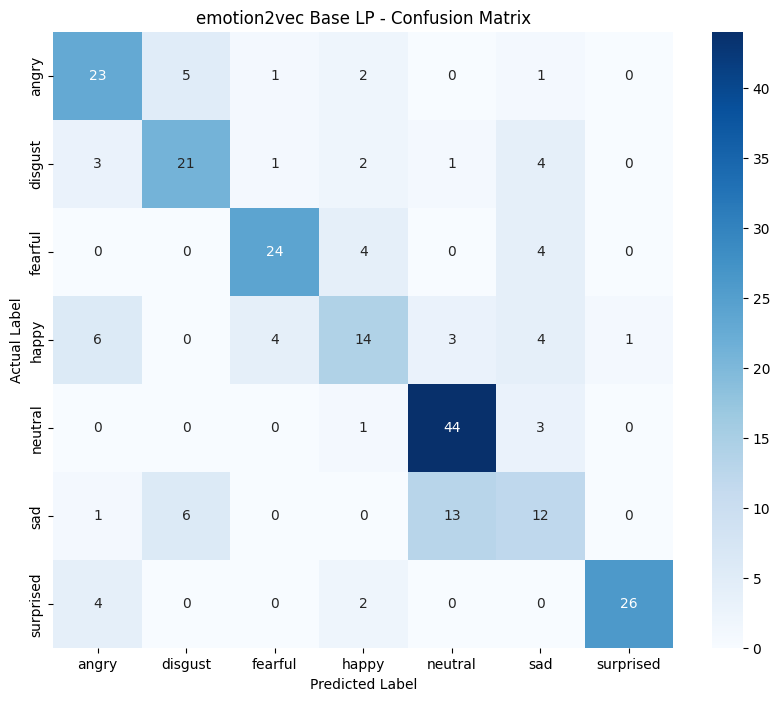

In [37]:
# ── Experiment 3b: emotion2vec (base) + Linear Probe ─────────────────
# This uses the non-distilled base model with a custom head trained on RAVDESS.

EMO2VEC_BASE_ID = "iic/emotion2vec_base"

import torch
import torch.nn as nn
from funasr import AutoModel

class Emotion2VecLinearProbe(nn.Module):
    def __init__(self, model_name: str, num_classes: int, dropout_prob: float = 0.25):
        super().__init__()

        # 1. Load the model (disable_update merely skips network version checks)
        self.backbone = AutoModel(model=model_name, device=str(DEVICE), disable_update=True)

        for param in self.backbone.model.parameters():
            param.requires_grad = False

        hidden_size = 768

        self.head = nn.Sequential(
            nn.Linear(hidden_size, 128),
            nn.ReLU(),
            nn.Dropout(dropout_prob),
            nn.Linear(128, num_classes)
        )

    def forward(self, input_values, padding_mask=None):
        res = self.backbone.model.extract_features(input_values, padding_mask=padding_mask)
        x = res['x']

        if padding_mask is not None:
            valid_mask = ~padding_mask.unsqueeze(-1)
            x = x * valid_mask
            sum_x = x.sum(dim=1)
            valid_counts = valid_mask.sum(dim=1).clamp(min=1)
            pooled_x = sum_x / valid_counts
        else:
            pooled_x = x.mean(dim=1)

        return self.head(pooled_x)

# 1. Instantiate
emo2vec_lp = Emotion2VecLinearProbe(EMO2VEC_BASE_ID, NUM_CLASSES, dropout_prob=experiment_3["model"]["dropout"]).to(DEVICE)

# 2. Training or Checkpoint Load
if USE_CHECKPOINTS:
    print(f"[Checkpoint] Loading emotion2vec probe from {E2V_PROBE_CKPT} ...")
    emo2vec_lp.load_state_dict(torch.load(E2V_PROBE_CKPT, map_location=DEVICE))
    emo2vec_lp.eval()
    print("Checkpoint loaded — training skipped.")
else:
    opt_e, sch_e, crit_e, ep_e, pat_e = build_training_components(
        model=emo2vec_lp,
        experiment_config=experiment_3,
        class_weights=class_weights
    )

    history_e, _ = train_model(
        model=emo2vec_lp,
        train_loader=train_loader,
        val_loader=val_loader,
        optimizer=opt_e,
        scheduler=sch_e,
        criterion=crit_e,
        epochs=ep_e,
        patience=pat_e,
        device=DEVICE,
        model_name="emotion2vec Base LP",
        use_amp=True
    )

# 3. Evaluate
e_labels, e_preds = predict_on_loader(emo2vec_lp, test_loader, DEVICE, desc="Testing emo2vec LP")
evaluate_test_set(e_labels, e_preds, ID2LABEL, model_name="emotion2vec Base LP")

# Multimodal Fusion — XGBoost FER Late Fusion

This section trains an XGBoost + Random Forest ensemble on hand-crafted blendshape
statistics and fuses its raw margin logits with each SER audio model via calibrated
temperature-scaled sum fusion.

| Block | Audio encoder | Visual model |
|---|---|---|
| 1 | Wav2Vec2 frozen linear probe | `xgb_fer_wrapper` |
| 2 | LoRA Wav2Vec2 probe | `xgb_fer_wrapper` |
| 3 | emotion2vec | `xgb_fer_wrapper` |

**Fusion strategy:** `output_margin=True` on the XGBoost booster gives unbounded logits
on the same scale as neural outputs. Both branches are temperature-scaled on the val split
then summed: $\hat{y} = \arg\max_k [w_a \hat{p}^{(a)}_k + w_v \hat{p}^{(v)}_k]$.


## Visual Feature Space: 53-Channel Blendshape Features

MediaPipe's face landmarker outputs 52 ARKit-compatible blendshape coefficients plus
the `_neutral` composite channel, giving **53 channels** per frame. Each coefficient
is a continuous value in $[0, 1]$ describing the activation of a specific facial muscle
group.

We use this representation instead of raw pixel frames for three reasons:
1. **Dimensionality:** a blendshape sequence $(T \times 53)$ is orders of magnitude
   smaller than video frames, making it tractable on a single GPU.
2. **Interpretability:** coefficients correspond directly to facial muscle actions.
3. **Robustness:** appearance-invariant — abstracts away lighting, skin tone, and camera angle.

`_neutral` is retained (unlike standard ARKit-52) because the scratch experiment
confirmed it carries discriminative signal for emotion classification.


In [38]:
ARKIT_52_COLS = [
    "_neutral",       # MediaPipe composite neutral — included as feature
    "browDownLeft", "browDownRight", "browInnerUp",
    "browOuterUpLeft", "browOuterUpRight",
    "cheekPuff", "cheekSquintLeft", "cheekSquintRight",
    "eyeBlinkLeft", "eyeBlinkRight",
    "eyeLookDownLeft", "eyeLookDownRight",
    "eyeLookInLeft", "eyeLookInRight",
    "eyeLookOutLeft", "eyeLookOutRight",
    "eyeLookUpLeft", "eyeLookUpRight",
    "eyeSquintLeft", "eyeSquintRight",
    "eyeWideLeft", "eyeWideRight",
    "jawForward", "jawLeft", "jawOpen", "jawRight",
    "mouthClose", "mouthDimpleLeft", "mouthDimpleRight",
    "mouthFrownLeft", "mouthFrownRight", "mouthFunnel",
    "mouthLeft", "mouthLowerDownLeft", "mouthLowerDownRight",
    "mouthPressLeft", "mouthPressRight", "mouthPucker", "mouthRight",
    "mouthRollLower", "mouthRollUpper",
    "mouthShrugLower", "mouthShrugUpper",
    "mouthSmileLeft", "mouthSmileRight",
    "mouthStretchLeft", "mouthStretchRight",
    "mouthUpperUpLeft", "mouthUpperUpRight",
    "noseSneerLeft", "noseSneerRight",
    "tongueOut",
]
assert len(ARKIT_52_COLS) == 53, f"Expected 53 (52 ARKit + _neutral), got {len(ARKIT_52_COLS)}"

_pretrain_emotions = {"neutral", "happy", "sad", "surprised", "angry", "fearful", "disgust"}
for _e in _pretrain_emotions:
    assert _e in LABEL2ID, (
        f"'{_e}' not found in LABEL2ID={LABEL2ID}. "
        f"Check EMOTION_MERGE_MAP or PRETRAIN_LABEL_REMAP."
    )

## Loading RAVDESS Blendshapes and Cross-Modal Alignment

Blendshape CSVs are stored on Google Drive, one file per utterance, named with the standard RAVDESS 7-field identifier (e.g. `02-01-06-01-02-01-12`). The loader parses these fields to recover emotion, intensity, statement, repetition, and actor metadata and remaps the native MediaPipe column layout to the canonical ARKit-52 order.

### Cross-modal alignment
Audio samples (from the HuggingFace dataset) and visual samples (from the local CSVs) are joined on the composite key:

$$	ext{key} = 	ext{emotion} \| 	ext{intensity} \| 	ext{statement} \| 	ext{repetition} \| 	ext{actor}$$

An inner join is used so only utterances with both audio and blendshape data are kept. `calm` emotion labels are mapped to `neutral` before key construction to maintain the shared label space established in the SER section. The resulting aligned DataFrame is then partitioned using the **same actor-disjoint split indices** as the SER experiments, guaranteeing that no actor seen in SER training appears in the multimodal test set.

In [39]:
import os
import math
import pandas as pd


def load_ravdess_blendshape_data(directory: str) -> list:
    samples = []
    filenames = sorted(f for f in os.listdir(directory) if f.endswith(".csv"))

    for filename in filenames:
        parts = filename.replace(".csv", "").split("-")
        if len(parts) != 7:
            continue
        try:
            _, _, emo_id, intensity_id, statement_id, repetition_id, actor_id = map(int, parts)
        except ValueError:
            continue

        emotion_name = RAVDESS_EMOTION_ID_TO_NAME.get(emo_id, "unknown")
        if emotion_name == "unknown":
            continue

        df = pd.read_csv(os.path.join(directory, filename))
        df = df.drop(columns=["timestamp_ms"], errors="ignore")  # _neutral retained as feature
        if "tongueOut" not in df.columns:
            df["tongueOut"] = 0.0
        df = df[ARKIT_52_COLS]

        features = df.values.astype(np.float32)
        assert features.shape[1] == 53, f"Column mismatch in {filename}: expected 53, got {features.shape[1]}"

        samples.append({
            "blendshape_features": features,
            "emotion":    emotion_name,
            "intensity":  INTENSITY_MAP.get(intensity_id,  "unknown"),
            "statement":  STATEMENT_MAP.get(statement_id,  "unknown"),
            "repetition": REPETITION_MAP.get(repetition_id, "unknown"),
            "actor":      int(actor_id),
        })

    print(f"Loaded {len(samples)} RAVDESS blendshape sequences from {directory}")
    return samples


blendshape_samples = load_ravdess_blendshape_data(DATA_PATH)
df_blendshapes = pd.DataFrame(blendshape_samples)

df_audio_raw = raw.to_pandas()
df_audio_raw["actor"] = df_audio_raw["actor"].astype(int)

def _make_key(emotion, intensity, statement, repetition, actor):
    return f"{emotion.lower()}|{intensity.lower()}|{statement.lower()}|{repetition.lower()}|{actor}"

df_audio_raw["merge_key"] = df_audio_raw.apply(
    lambda r: _make_key(
        EMOTION_MERGE_MAP.get(r["emotion"], r["emotion"]),
        r["emotional_intensity"], r["statement"], r["repetition"], r["actor"],
    ), axis=1
)
df_blendshapes["merge_key"] = df_blendshapes.apply(
    lambda r: _make_key(
        EMOTION_MERGE_MAP.get(r["emotion"], r["emotion"]),
        r["intensity"], r["statement"], r["repetition"], r["actor"],
    ), axis=1
)
df_blendshapes = df_blendshapes.drop_duplicates(subset=["merge_key"], keep="first")

df_aligned = pd.merge(
    df_audio_raw.reset_index(),
    df_blendshapes,
    on="merge_key",
    how="inner",
    suffixes=("_audio", "_blendshape"),
)

Loaded 2880 RAVDESS blendshape sequences from /content/drive/My Drive/ravdess-videos/blendshapes


In [40]:
print(f"Aligned pairs: {len(df_aligned)}  "
      f"(audio={len(df_audio_raw)}, blendshape={len(blendshape_samples)})")

aligned_train_df = df_aligned[df_aligned["index"].isin(train_indices)].copy()
aligned_val_df  = df_aligned[df_aligned["index"].isin(val_indices)].copy()
aligned_test_df  = df_aligned[df_aligned["index"].isin(test_indices)].copy()

aligned_test_indices = aligned_test_df["index"].tolist()
aligned_val_indices = aligned_val_df["index"].tolist()

print(f"Aligned split sizes — "
      f"train: {len(aligned_train_df)}  "
      f"val: {len(aligned_val_df)}  "
      f"test: {len(aligned_test_df)}")

Aligned pairs: 1440  (audio=1440, blendshape=2880)
Aligned split sizes — train: 960  val: 240  test: 240


## FER Feature Extraction

Raw variable-length blendshape sequences are stored directly from the CSV files  passed directly to `extract_stats_ratio_np`, which computes statistics from real frames only.


In [41]:
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupKFold
from sklearn.metrics import accuracy_score, f1_score
from torch.utils.data import Dataset

fer_actor_col = "actor_audio" if "actor_audio" in aligned_train_df.columns else "actor"
fer_emotion_col = "emotion_audio" if "emotion_audio" in aligned_train_df.columns else "emotion"

def _map_emotion(name: str) -> int:
    name = str(name).lower().strip()
    name = EMOTION_MERGE_MAP.get(name, name)
    return LABEL2ID[name]


# ── Sequences stay raw (variable-length); lengths computed dynamically in collate ─
# XGBoost/RF computes statistics per sample directly from raw arrays.
# MLP pads per-batch inside blendshape_collate_fn — no global framing needed.
num_features = len(ARKIT_52_COLS)  # 53 (includes _neutral)
print(f"Feature dim: {num_features}  |  batches padded dynamically — no fixed-length framing")

Feature dim: 53  |  batches padded dynamically — no fixed-length framing


## FER Visual Model — XGBoost + Random Forest Ensemble

The visual FER backbone is an **XGBoost + Random Forest ensemble** trained on a
**369-dimensional hand-crafted feature vector** per utterance:

- **7 statistical moments × 53 channels** = 371 base features (mean, std, max, min,
  range, Δmean, Δmax from first-order finite differences)
- **5 inter-group ratios** (brow/eye, brow/mouth, eye/mouth, cheek/mouth, cheek/brow)

Could have also included 2nd order deriviate calculations, but results are good enough..


Class imbalance is corrected via `compute_sample_weight("balanced")`.

for late fusion, wrapper is used for logits translation,`logits = xgb_rf_clf.get_booster().predict(xgb.DMatrix(feats), output_margin=True)`


In [42]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

class BlendshapeDataset(Dataset):
    """Raw variable-length blendshape sequences; collate pads per batch."""
    def __init__(self, X, y):
        self.X = X; self.y = y
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        x = torch.tensor(self.X[i], dtype=torch.float32).transpose(0, 1)
        return x, torch.tensor(self.y[i], dtype=torch.long)

def blendshape_collate_fn(batch):
    xs, ys = zip(*batch)
    lengths = torch.tensor([x.shape[-1] for x in xs], dtype=torch.long)
    max_len = lengths.max().item()
    padded  = torch.stack([F.pad(x, (0, max_len - x.shape[-1])) for x in xs])
    return padded, torch.tensor(ys, dtype=torch.long), lengths

class AlignedBSDataset(Dataset):
    """Ordered dataset for fusion — do NOT shuffle."""
    def __init__(self, X, y):
        self.X = X; self.y = y
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        return (torch.tensor(self.X[i], dtype=torch.float32).transpose(0, 1),
                torch.tensor(self.y[i], dtype=torch.long))

In [43]:
X_train  = aligned_train_df["blendshape_features"].tolist()
y_train  = [_map_emotion(e) for e in aligned_train_df[fer_emotion_col]]

X_val_bs = aligned_val_df["blendshape_features"].tolist()
y_val_bs = [_map_emotion(e) for e in aligned_val_df[fer_emotion_col]]

X_test_bs = aligned_test_df["blendshape_features"].tolist()
y_test_bs  = [_map_emotion(e) for e in aligned_test_df[fer_emotion_col]]

num_features = len(ARKIT_52_COLS)
print(f"FER arrays ready — train: {len(X_train)}, val: {len(X_val_bs)}, test: {len(X_test_bs)}")

FER arrays ready — train: 960, val: 240, test: 240


In [44]:
import xgboost as xgb
import numpy as np
import torch
from sklearn.metrics import classification_report, accuracy_score
from sklearn.utils.class_weight import compute_sample_weight

# ── Numpy feature extractor ──
_BROW_IDX       = [1, 2, 3, 4, 5]
_EYE_IDX        = list(range(9, 23))
_MOUTH_JAW_IDX  = list(range(23, 50))
_CHEEK_NOSE_IDX = [6, 7, 8, 50, 51]

def extract_stats_ratio_np(X_list, lengths_list):
    """Convert a list of padded blendshape arrays to 369-dim feature vectors."""
    eps  = 1e-6
    rows = []
    for x, L in zip(X_list, lengths_list):
        x = np.asarray(x, dtype=np.float32)[:L]
        vel  = np.gradient(x, axis=0).astype(np.float32)

        m  = x.mean(0);  s  = x.std(0)
        mx = x.max(0);   mn = x.min(0);  rng = mx - mn
        vm = vel.mean(0); vx = vel.max(0)

        b_avg = m[_BROW_IDX].mean();       e_avg = m[_EYE_IDX].mean()
        mo_avg = m[_MOUTH_JAW_IDX].mean(); c_avg = m[_CHEEK_NOSE_IDX].mean()
        ratios = np.array([
            b_avg / (e_avg  + eps), b_avg  / (mo_avg + eps),
            e_avg / (mo_avg + eps), c_avg  / (mo_avg + eps),
            c_avg / (b_avg  + eps),
        ])
        rows.append(np.concatenate([m, s, mx, mn, rng, vm, vx, ratios]))
    return np.stack(rows)

# ── Training ──
print("Extracting 369-dim features for XGBoost training…")
X_tr_xgb = extract_stats_ratio_np(X_train,  [len(x) for x in X_train])
X_vl_xgb = extract_stats_ratio_np(X_val_bs, [len(x) for x in X_val_bs])
X_te_xgb = extract_stats_ratio_np(X_test_bs,[len(x) for x in X_test_bs])

sample_weights = compute_sample_weight("balanced", y=y_train)

xgb_rf_clf = xgb.XGBRFClassifier(
    n_estimators=300,
    learning_rate=1.0,
    max_depth=10,
    subsample=0.8,
    colsample_bytree=0.3,
    random_state=SEED,
    eval_metric="mlogloss"
)

xgb_rf_clf.fit(X_tr_xgb, y_train, sample_weight=sample_weights)

# ── Evaluation ──
rf_preds = xgb_rf_clf.predict(X_te_xgb)
ens_preds = rf_preds

print(f"\nXGBRFClassifier FER — aligned test set:")
print(classification_report(
    y_test_bs, rf_preds,
    labels=list(range(NUM_CLASSES)),
    target_names=[ID2LABEL[i] for i in range(NUM_CLASSES)],
    zero_division=0,
))

# For compatibility with fusion blocks that expect a callable visual model returning logits
def xgb_fer_model(x_batch, lengths=None):
    x_np = x_batch.detach().cpu().numpy()
    B, F, T = x_np.shape
    lens = (lengths.cpu().numpy().astype(int) if lengths is not None else [T] * B)
    seqs = [x_np[i, :, :lens[i]].T for i in range(B)]
    feats = extract_stats_ratio_np(seqs, lens)
    # output_margin=True returns raw logits for sum-fusion
    logits = xgb_rf_clf.get_booster().predict(xgb.DMatrix(feats), output_margin=True)
    return torch.tensor(logits, dtype=torch.float32)

xgb_fer_wrapper = xgb_fer_model
print("Native XGBRFClassifier trained. Model reference 'xgb_fer_wrapper' updated.")

Extracting 369-dim features for XGBoost training…

XGBRFClassifier FER — aligned test set:
              precision    recall  f1-score   support

       angry       0.87      0.84      0.86        32
     disgust       0.78      0.66      0.71        32
     fearful       0.58      0.56      0.57        32
       happy       0.78      1.00      0.88        32
     neutral       0.95      0.42      0.58        48
         sad       0.40      0.84      0.55        32
   surprised       0.50      0.34      0.41        32

    accuracy                           0.65       240
   macro avg       0.70      0.67      0.65       240
weighted avg       0.71      0.65      0.65       240

Native XGBRFClassifier trained. Model reference 'xgb_fer_wrapper' updated.


## Calibration & Sum-Fusion Utilities

### Temperature Scaling

To prevent an overconfident modality from dominating the fusion, we calibrate the logits of each branch on the validation split prior to summation. We use L-BFGS (max 500 iterations) to find the scaling factor $T$ that minimises validation cross-entropy:

$$\hat{p}_k = \text{softmax}\left(\frac{z_k}{T}\right)$$

The fitted temperatures are frozen and applied directly to the test set, preserving its independence.

### Calibrated Sum-Fusion

The calibrated probabilities are fused using a weighted late-fusion baseline:

$$\hat{y}_i = \arg\max_k \left[ w_a \cdot \hat{p}^{(a)}_k + w_v \cdot \hat{p}^{(v)}_k \right]$$

We set $w_a = w_v = 1.0$ (equal weighting) as the baseline for our hybrid approach to beat.

In [45]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
from tqdm.auto import tqdm

def get_logits_and_labels(model_to_eval, data_loader, device):
    """
    Extract logits and labels from a model and loader.
    Handles dict batches (audio) and tuple batches (blendshapes, with lengths).
    Supports both PyTorch modules and functional wrappers (like XGBoost).
    """
    # Only call .eval() if the model is a native PyTorch module
    if isinstance(model_to_eval, nn.Module):
        model_to_eval.eval()

    all_logits = []
    all_labels = []

    with torch.no_grad():
        for batch in tqdm(data_loader, desc="Extracting Logits", leave=False):
            if isinstance(batch, dict):
                # Audio data case
                x = batch["input_values"].to(device)
                y = batch["labels"]
                logits = model_to_eval(x)
            else:
                # Blendshape data case (x, y, lengths)
                x, y, lengths = batch
                x, lengths = x.to(device), lengths.to(device)
                logits = model_to_eval(x, lengths)

            # Ensure conversion to numpy for calibration step
            all_logits.append(logits.detach().cpu().numpy() if torch.is_tensor(logits) else logits)
            all_labels.append(y.detach().cpu().numpy() if torch.is_tensor(y) else np.array(y))

    return np.vstack(all_logits), np.concatenate(all_labels)

class TemperatureScaler(nn.Module):
    """
    Temperature scaling module for logit calibration.
    """
    def __init__(self, device):
        super(TemperatureScaler, self).__init__()
        self.device = device
        self.temperature = nn.Parameter(torch.ones(1).to(device))

    def forward(self, logits):
        return logits / self.temperature

    def fit(self, logits, labels):
        logits_t = torch.tensor(logits, dtype=torch.float32, device=self.device)
        labels_t = torch.tensor(labels, dtype=torch.long, device=self.device)

        optimizer = optim.LBFGS([self.temperature], lr=0.01, max_iter=500)
        criterion = nn.CrossEntropyLoss()

        def eval_loss():
            optimizer.zero_grad()
            loss = criterion(self.forward(logits_t), labels_t)
            loss.backward()
            return loss

        optimizer.step(eval_loss)
        return self

    def calibrate(self, logits):
        self.eval()
        logits_t = torch.tensor(logits, dtype=torch.float32, device=self.device)
        with torch.no_grad():
            calibrated = self.forward(logits_t)
        return calibrated.cpu().numpy()

def verify_label_alignment(audio_labels, visual_labels, split_name="test"):
    if len(audio_labels) != len(visual_labels):
        raise ValueError(f"{split_name}: label length mismatch ({len(audio_labels)} vs {len(visual_labels)})")
    if not np.array_equal(np.asarray(audio_labels), np.asarray(visual_labels)):
        raise ValueError(f"{split_name}: label mismatch between modalities")

def run_calibrated_sum_fusion(
    audio_test_logits, audio_test_labels,
    audio_val_logits, audio_val_labels,
    visual_test_logits, visual_test_labels,
    visual_val_logits, visual_val_labels,
    device,
    calibrate_audio=True,
    calibrate_visual=True,
    modality_weights=(1.0, 1.0),
):
    verify_label_alignment(audio_test_labels, visual_test_labels, split_name="test")
    verify_label_alignment(audio_val_labels, visual_val_labels, split_name="val")

    audio_test_cal = np.array(audio_test_logits, copy=True)
    visual_test_cal = np.array(visual_test_logits, copy=True)

    if calibrate_audio:
        ts_audio = TemperatureScaler(device).fit(audio_val_logits, audio_val_labels)
        audio_test_cal = ts_audio.calibrate(audio_test_logits)

    if calibrate_visual:
        ts_visual = TemperatureScaler(device).fit(visual_val_logits, visual_val_labels)
        visual_test_cal = ts_visual.calibrate(visual_test_logits)

    wa, wv = modality_weights
    fused_probs = (
        wa * torch.softmax(torch.tensor(audio_test_cal), dim=-1)
        + wv * torch.softmax(torch.tensor(visual_test_cal), dim=-1)
    )
    fused_preds = torch.argmax(fused_probs, dim=-1).cpu().numpy()

    return fused_preds, {
        "audio_test_cal": audio_test_cal,
        "visual_test_cal": visual_test_cal,
    }

## Aligned Fusion DataLoaders

DataLoaders are constructed with `shuffle=False` so that batch $i$ of the audio loader and
batch $i$ of the blendshape loader cover the **same utterances** in the same order, ensuring
1:1 alignment during fusion.

Note: only **val** and **test** loaders are needed


In [46]:
aligned_test_ds_audio = Subset(dataset, aligned_test_indices)
aligned_val_ds_audio  = Subset(dataset, aligned_val_indices)

ordered_test_audio_loader  = DataLoader(aligned_test_ds_audio,  batch_size=64, shuffle=False, collate_fn=collate_fn)
ordered_val_audio_loader   = DataLoader(aligned_val_ds_audio,   batch_size=64, shuffle=False, collate_fn=collate_fn)

ordered_test_bs_loader  = DataLoader(AlignedBSDataset(X_test_bs, y_test_bs), batch_size=64, shuffle=False, collate_fn=blendshape_collate_fn)
ordered_val_bs_loader   = DataLoader(AlignedBSDataset(X_val_bs,  y_val_bs),  batch_size=64, shuffle=False, collate_fn=blendshape_collate_fn)
ordered_train_bs_loader = DataLoader(AlignedBSDataset(X_train,   y_train), batch_size=64, shuffle=False, collate_fn=blendshape_collate_fn)

In [47]:
def _np_labels(arr):
    return arr.cpu().numpy() if torch.is_tensor(arr) else np.asarray(arr)

def _report(y_true_np, preds):
    labels, names = zip(*sorted([(i, ID2LABEL[i]) for i in set(y_true_np.tolist())]))
    print(classification_report(y_true_np, preds, labels=list(labels), target_names=list(names), zero_division=0))

def run_late_fusion_experiment(name, audio_model, visual_model,
                               ordered_test_audio_loader, ordered_val_audio_loader,
                               ordered_test_bs_loader,   ordered_val_bs_loader,
                               device, calibrate_audio=True, calibrate_visual=True,
                               modality_weights=(1.0, 1.0)):
    """Calibrated temperature-scaled sum fusion."""
    print(f"\n[Late Fusion] {name}")
    at_l, at_y = get_logits_and_labels(audio_model,  ordered_test_audio_loader, device)
    av_l, av_y = get_logits_and_labels(audio_model,  ordered_val_audio_loader,  device)
    vt_l, vt_y = get_logits_and_labels(visual_model, ordered_test_bs_loader,    device)
    vv_l, vv_y = get_logits_and_labels(visual_model, ordered_val_bs_loader,     device)
    preds, cal = run_calibrated_sum_fusion(
        audio_test_logits=at_l, audio_test_labels=at_y,
        audio_val_logits=av_l,  audio_val_labels=av_y,
        visual_test_logits=vt_l, visual_test_labels=vt_y,
        visual_val_logits=vv_l,  visual_val_labels=vv_y,
        device=device, calibrate_audio=calibrate_audio, calibrate_visual=calibrate_visual,
        modality_weights=modality_weights,
    )
    _report(_np_labels(vt_y), preds)
    return {"preds": preds, "y_true": _np_labels(vt_y), "calibrated": cal}


## Fusion Block 1 — Wav2Vec2 Frozen Probe × XGBoost FER

**Prerequisite:** `wav2vec2_probe` trained (Experiment 1) and `xgb_fer_wrapper` ready.

Audio logits: Wav2Vec2 frozen probe → `get_logits_and_labels`.
Visual logits: XGBoost raw margins via `output_margin=True`.
Both temperature-calibrated on val, then summed.


In [48]:
late_w2v = run_late_fusion_experiment(
    name="Wav2Vec2 Frozen + XGBoost FER",
    audio_model=wav2vec2_probe, visual_model=xgb_fer_wrapper,
    ordered_test_audio_loader=ordered_test_audio_loader,
    ordered_val_audio_loader=ordered_val_audio_loader,
    ordered_test_bs_loader=ordered_test_bs_loader,
    ordered_val_bs_loader=ordered_val_bs_loader,
    device=DEVICE,
)
fused_preds    = late_w2v["preds"]
bs_test_labels = late_w2v["y_true"]


[Late Fusion] Wav2Vec2 Frozen + XGBoost FER


Extracting Logits:   0%|          | 0/4 [00:00<?, ?it/s]

Extracting Logits:   0%|          | 0/4 [00:00<?, ?it/s]

Extracting Logits:   0%|          | 0/4 [00:00<?, ?it/s]

Extracting Logits:   0%|          | 0/4 [00:00<?, ?it/s]

              precision    recall  f1-score   support

       angry       0.88      0.94      0.91        32
     disgust       0.93      0.78      0.85        32
     fearful       0.94      0.50      0.65        32
       happy       0.88      0.94      0.91        32
     neutral       0.84      0.96      0.89        48
         sad       0.57      0.78      0.66        32
   surprised       0.86      0.78      0.82        32

    accuracy                           0.82       240
   macro avg       0.84      0.81      0.81       240
weighted avg       0.84      0.82      0.82       240



## Fusion Block 2 — LoRA Wav2Vec2 × XGBoost FER

**Prerequisite:** `lora_model` trained (Experiment 2) and `xgb_fer_wrapper` ready.

Same fusion strategy as Block 1 with the LoRA-adapted backbone providing audio logits.


In [54]:
late_lora = run_late_fusion_experiment(
    name="LoRA Wav2Vec2 + XGBoost FER",
    audio_model=lora_model, visual_model=xgb_fer_wrapper,
    ordered_test_audio_loader=ordered_test_audio_loader,
    ordered_val_audio_loader=ordered_val_audio_loader,
    ordered_test_bs_loader=ordered_test_bs_loader,
    ordered_val_bs_loader=ordered_val_bs_loader,
    device=DEVICE,
)
fused_preds_lora = late_lora["preds"]


[Late Fusion] LoRA Wav2Vec2 + XGBoost FER


Extracting Logits:   0%|          | 0/4 [00:00<?, ?it/s]

Extracting Logits:   0%|          | 0/4 [00:00<?, ?it/s]

Extracting Logits:   0%|          | 0/4 [00:00<?, ?it/s]

Extracting Logits:   0%|          | 0/4 [00:00<?, ?it/s]

              precision    recall  f1-score   support

       angry       0.82      1.00      0.90        32
     disgust       0.84      0.66      0.74        32
     fearful       0.88      0.91      0.89        32
       happy       1.00      0.94      0.97        32
     neutral       0.87      0.98      0.92        48
         sad       0.69      0.69      0.69        32
   surprised       1.00      0.84      0.92        32

    accuracy                           0.87       240
   macro avg       0.87      0.86      0.86       240
weighted avg       0.87      0.87      0.86       240



## Fusion Block 3 — emotion2vec × XGBoost FER

**Prerequisite:** `emotion2vec_model` initialised (Experiment 3) and `xgb_fer_wrapper` ready.



In [55]:
# ── Fusion Block 3: emotion2vec LP + XGBoost FER ─────────────────
# This now uses the trained emo2vec_lp (Linear Probe) model.

# 1. Extract Logits for Audio (emo2vec_lp)
print("Extracting emotion2vec LP logits...")
at_l_e, at_y_e = get_logits_and_labels(emo2vec_lp, ordered_test_audio_loader, DEVICE)
av_l_e, av_y_e = get_logits_and_labels(emo2vec_lp, ordered_val_audio_loader,  DEVICE)

# 2. Extract Logits for Visual (XGBoost)
print("Extracting XGBoost FER logits...")
vt_l_e, vt_y_e = get_logits_and_labels(xgb_fer_wrapper, ordered_test_bs_loader, DEVICE)
vv_l_e, vv_y_e = get_logits_and_labels(xgb_fer_wrapper, ordered_val_bs_loader,  DEVICE)

# 3. Run Calibrated Sum Fusion
fused_preds_emo2vec_sf, _ = run_calibrated_sum_fusion(
    audio_test_logits=at_l_e,  audio_test_labels=at_y_e,
    audio_val_logits=av_l_e,    audio_val_labels=av_y_e,
    visual_test_logits=vt_l_e,     visual_test_labels=vt_y_e,
    visual_val_logits=vv_l_e,       visual_val_labels=vv_y_e,
    device=DEVICE,
)

# 4. Report Results
print("\n[Late Fusion] emotion2vec LP + XGBoost FER")
_report(vt_y_e, fused_preds_emo2vec_sf)

# Update global variables for summary table
test_y_emo2vec_sf = vt_y_e

Extracting emotion2vec LP logits...


Extracting Logits:   0%|          | 0/4 [00:00<?, ?it/s]

Extracting Logits:   0%|          | 0/4 [00:00<?, ?it/s]

Extracting XGBoost FER logits...


Extracting Logits:   0%|          | 0/4 [00:00<?, ?it/s]

Extracting Logits:   0%|          | 0/4 [00:00<?, ?it/s]


[Late Fusion] emotion2vec LP + XGBoost FER
              precision    recall  f1-score   support

       angry       0.80      0.88      0.84        32
     disgust       0.86      0.75      0.80        32
     fearful       0.93      0.81      0.87        32
       happy       0.86      1.00      0.93        32
     neutral       0.85      0.96      0.90        48
         sad       0.73      0.69      0.71        32
   surprised       1.00      0.88      0.93        32

    accuracy                           0.86       240
   macro avg       0.86      0.85      0.85       240
weighted avg       0.86      0.86      0.86       240



## Final Summary Table

Accuracy and macro-F1 for all three SER baselines and their corresponding late fusion
variants using the XGBoost + RF visual FER model.
All results on the 240-sample actor-disjoint test split.


In [56]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, recall_score
from IPython.display import display

def _score(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    labels = sorted(list(set(y_true.tolist())))

    # Weighted Accuracy is typically equivalent to Weighted Recall
    wa = recall_score(y_true, y_pred, labels=labels, average='weighted', zero_division=0)
    wf1 = f1_score(y_true, y_pred, labels=labels, average='weighted', zero_division=0)

    return {
        'Accuracy': round(accuracy_score(y_true, y_pred), 4),
        'Weighted_Acc': round(wa, 4),
        'Macro_F1': round(f1_score(y_true, y_pred, labels=labels, average='macro', zero_division=0), 4),
        'Weighted_F1': round(wf1, 4)
    }

summary_rows = [
    {'Model': 'Wav2Vec2 Frozen Probe',        **_score(all_labels,           all_preds)},
    {'Model': 'LoRA Wav2Vec',                 **_score(lora_labels,          lora_preds)},
    {'Model': 'emotion2vec Base LP',          **_score(e_labels,             e_preds)},
    {'Model': 'XGBOOSTRF FER',                **_score(y_test_bs,            ens_preds)},
    {'Model': 'Wav2Vec2 + FER',               **_score(bs_test_labels,       fused_preds)},
    {'Model': 'LoRA Wav2Vec2 + FER',          **_score(bs_test_labels,       fused_preds_lora)},
    {'Model': 'emotion2vec Base LP + FER',    **_score(test_y_emo2vec_sf,    fused_preds_emo2vec_sf)},
]

summary_df = pd.DataFrame(summary_rows)
print('Summary (XGBoost FER late fusion):')
display(summary_df)

Summary (XGBoost FER late fusion):


,Model,Accuracy,Weighted_Acc,Macro_F1,Weighted_F1
0,Wav2Vec2 Frozen Probe,0.7125,0.7125,0.6957,0.7052
1,LoRA Wav2Vec,0.7250,0.7250,0.7020,0.7110
2,emotion2vec Base LP,0.6833,0.6833,0.6681,0.6774
3,XGBOOSTRF FER,0.6500,0.6500,0.6500,0.6453
4,Wav2Vec2 + FER,0.8208,0.8208,0.8128,0.8181
5,LoRA Wav2Vec2 + FER,0.8667,0.8667,0.8604,0.8645
6,emotion2vec Base LP + FER,0.8583,0.8583,0.8536,0.8568


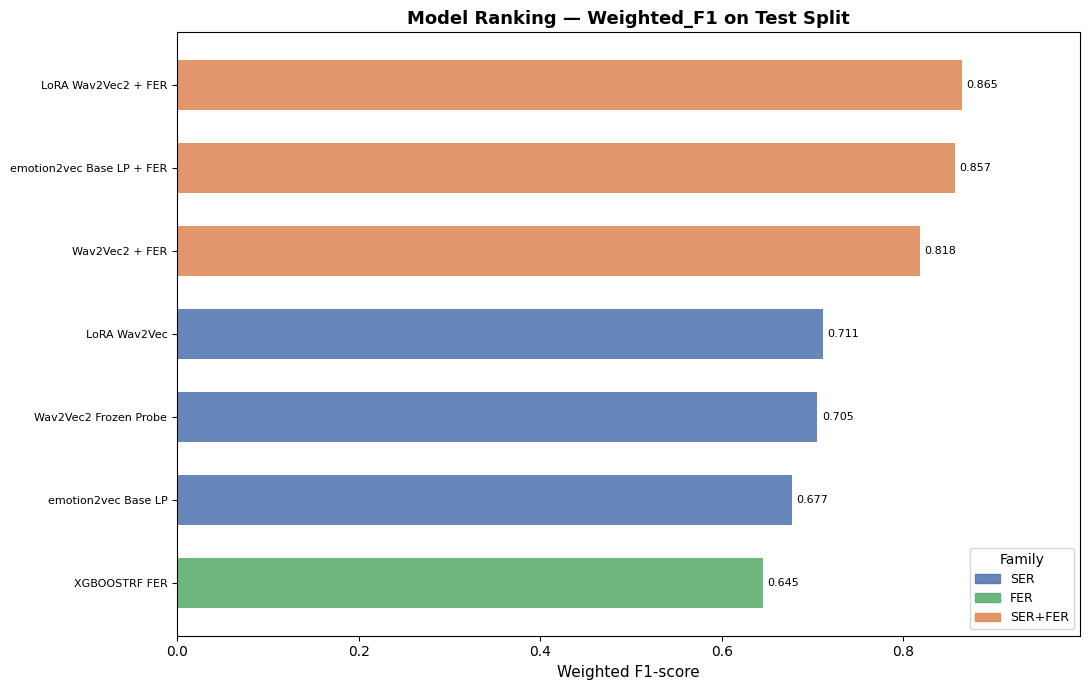

In [57]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Build a colour map by model family
def _family(name):
    # Prioritize fusion models, then standalone FER, then SER
    if " + FER" in name: return "SER+FER"
    if "XGBOOSTRF FER" in name: return "FER"
    return "SER"

FAMILY_COLORS = {"SER": "#4C72B0", "FER": "#55A868", "SER+FER": "#DD8452"}

# Use Weighted_F1 as requested
metric_col = "Weighted_F1"
plot_df = summary_df.sort_values(metric_col, ascending=True).copy()
plot_df["_color"] = plot_df["Model"].apply(lambda m: FAMILY_COLORS[_family(m)])

fig, ax = plt.subplots(figsize=(11, 7))
bars = ax.barh(range(len(plot_df)), plot_df[metric_col],
               color=plot_df["_color"], alpha=0.85, height=0.6)
ax.set_yticks(range(len(plot_df)))
ax.set_yticklabels(plot_df["Model"],
                   fontsize=8)
ax.set_xlabel("Weighted F1-score", fontsize=11)
ax.set_title(f"Model Ranking — {metric_col} on Test Split", fontsize=13, fontweight="bold")
ax.set_xlim(0, min(1.0, plot_df[metric_col].max() + 0.13))
ax.axvline(0, color="black", linewidth=0.6)

for bar, val in zip(bars, plot_df[metric_col]):
    ax.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height() / 2,
            f"{val:.3f}", va="center", fontsize=8)

legend_handles = [mpatches.Patch(color=c, label=l, alpha=0.85)
                  for l, c in FAMILY_COLORS.items()]
ax.legend(handles=legend_handles, loc="lower right", title="Family", fontsize=9)
plt.tight_layout()
plt.show()

=== COMPREHENSIVE MULTIMODAL EVALUATION ===


--- Intensity Stratified Performance Comparison ---


Intensity,normal,strong
Model,,
Wav2Vec2 (Audio),0.6406,0.7946
Wav2Vec2 + FER,0.7422,0.9107
LoRA W2V (Audio),0.6406,0.8214
LoRA W2V + FER,0.8359,0.9018
emotion2vec Base LP (Audio),0.5781,0.8036
emotion2vec Base LP + FER,0.8203,0.9018
XGBoost (Visual),0.6406,0.6607



--- Detailed Metrics: Wav2Vec2 + FER ---
              precision    recall  f1-score   support

       angry       0.88      0.94      0.91        32
     disgust       0.93      0.78      0.85        32
     fearful       0.94      0.50      0.65        32
       happy       0.88      0.94      0.91        32
     neutral       0.84      0.96      0.89        48
         sad       0.57      0.78      0.66        32
   surprised       0.86      0.78      0.82        32

    accuracy                           0.82       240
   macro avg       0.84      0.81      0.81       240
weighted avg       0.84      0.82      0.82       240


--- Detailed Metrics: LoRA W2V + FER ---
              precision    recall  f1-score   support

       angry       0.82      1.00      0.90        32
     disgust       0.84      0.66      0.74        32
     fearful       0.88      0.91      0.89        32
       happy       1.00      0.94      0.97        32
     neutral       0.87      0.98      0.92     

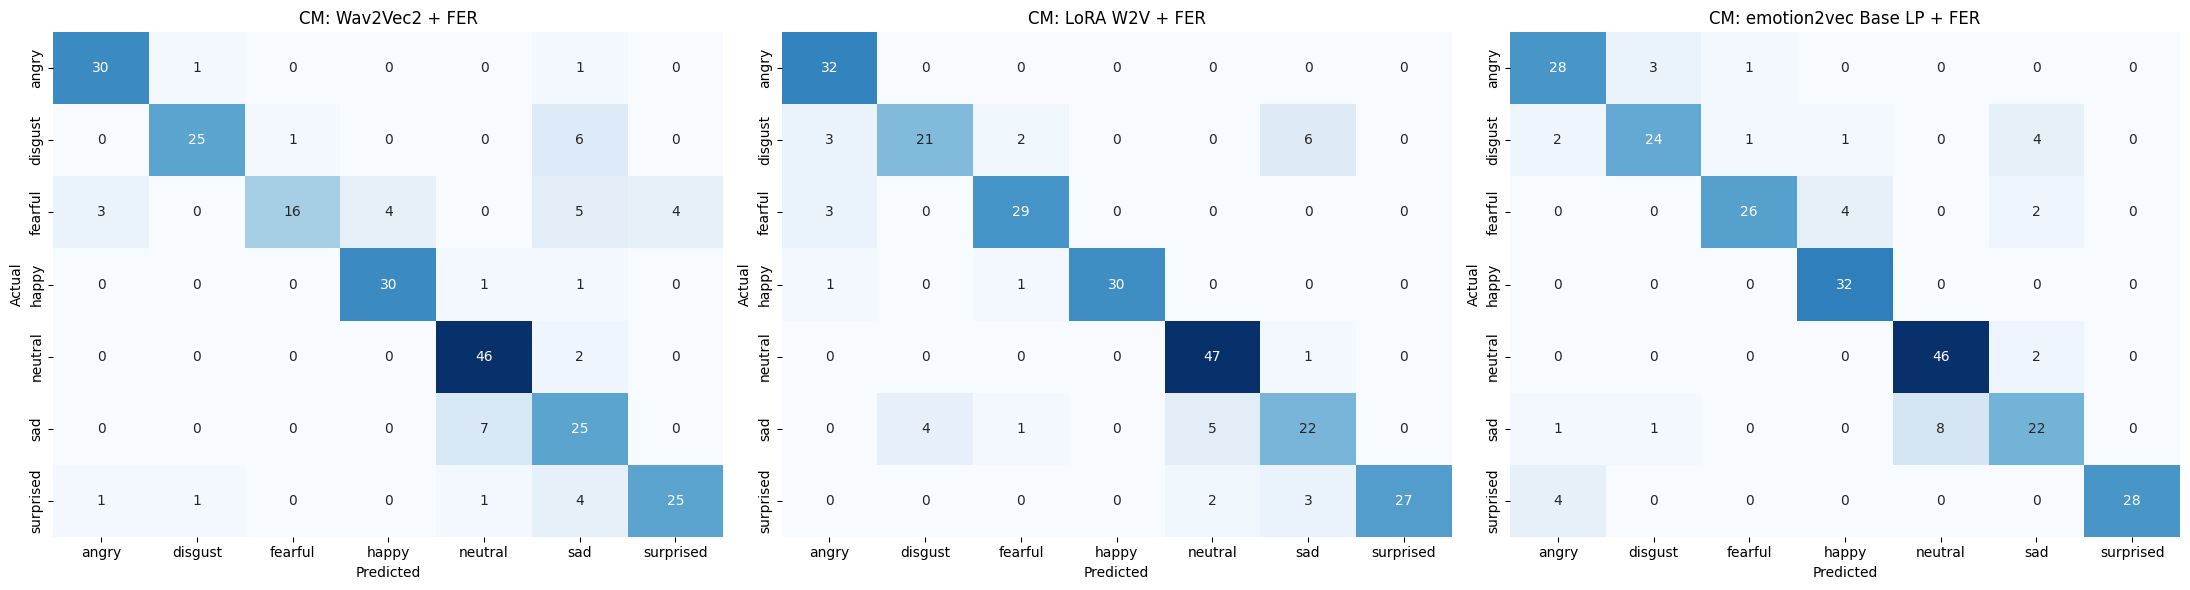

In [59]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import pandas as pd
import numpy as np

# 1. Stratified Intensity Analysis
def evaluate_stratified_intensity(y_true, y_pred, df_aligned_test):
    """Splits results by 'normal' and 'strong' intensity and calculates accuracy."""
    intensities = df_aligned_test["emotional_intensity"].values
    results = []
    for intensity in ["normal", "strong"]:
        mask = (intensities == intensity)
        if mask.any():
            acc = accuracy_score(y_true[mask], y_pred[mask])
            results.append({"Intensity": intensity, "Accuracy": round(acc, 4), "Count": int(mask.sum())})
    return results

# 2. Detailed Performance Visualisation
# We include the unimodal baselines (Audio-only and Visual-only) plus the Fusion variants
evaluation_suite = [
    ("Wav2Vec2 (Audio)", all_labels, all_preds),
    ("LoRA W2V (Audio)", lora_labels, lora_preds),
    ("emotion2vec Base LP (Audio)", e_labels, e_preds),
    ("XGBoost (Visual)", y_test_bs, ens_preds),
    ("Wav2Vec2 + FER", bs_test_labels, fused_preds),
    ("LoRA W2V + FER", bs_test_labels, fused_preds_lora),
    ("emotion2vec Base LP + FER", test_y_emo2vec_sf, fused_preds_emo2vec_sf)
]

print("=== COMPREHENSIVE MULTIMODAL EVALUATION ===\n")

# Intensity Stratification Table
strat_rows = []
for name, y_true, y_pred in evaluation_suite:
    res = evaluate_stratified_intensity(np.asarray(y_true), np.asarray(y_pred), aligned_test_df)
    for r in res:
        r["Model"] = name
        strat_rows.append(r)

strat_df = pd.DataFrame(strat_rows)
print("\n--- Intensity Stratified Performance Comparison ---")
pivot_df = strat_df.pivot(index="Model", columns="Intensity", values="Accuracy")

# Reorder to keep family groups together
pivot_df = pivot_df.reindex([
    "Wav2Vec2 (Audio)", "Wav2Vec2 + FER",
    "LoRA W2V (Audio)", "LoRA W2V + FER",
    "emotion2vec Base LP (Audio)", "emotion2vec Base LP + FER",
    "XGBoost (Visual)"
])
display(pivot_df)

# Detailed Reports for the 3 Fusion Models
fig, axes = plt.subplots(1, 3, figsize=(22, 6))
fusion_only = [m for m in evaluation_suite if " + FER" in m[0]]

for i, (name, y_true, y_pred) in enumerate(fusion_only):
    # Report
    print(f"\n--- Detailed Metrics: {name} ---")
    labels = sorted(list(set(y_true)))
    names = [ID2LABEL[l] for l in labels]
    print(classification_report(y_true, y_pred, target_names=names, zero_division=0))

    # Confusion Matrix Plot
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=names, yticklabels=names, ax=axes[i], cbar=False)
    axes[i].set_title(f"CM: {name}")
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Actual")

plt.tight_layout()
plt.show()